In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import constants as const
from scipy.optimize import minimize
from scipy.spatial import ConvexHull
from matplotlib.colors import LightSource
import itertools

In [12]:
def razdalja_locna(phi1, theta1, phi2, theta2):
    '''implementacija ločne razdalje - NI TREBA?!
        phi - horizontalni kot, zasuk
        theta - vertikalni kot, naklon
        polmer krogle je 1'''
    return np.arccos(np.sin(np.pi/2-theta1)*np.sin(np.pi/2-theta2) + np.cos(np.pi/2-theta1)*np.cos(np.pi/2-theta2)*np.cos(phi2-phi1))
def razdalja(phi1, theta1, phi2, theta2):
    '''implementacija linearne razdalje
        phi - horizontalni kot, zasuk
        theta - vertikalni kot, naklon'''
    r = 1 #enotska krogla
    x1 = r * np.sin(theta1) * np.cos(phi1)
    y1 = r * np.sin(theta1) * np.sin(phi1)
    z1 = r * np.cos(theta1)
    x2 = r * np.sin(theta2) * np.cos(phi2)
    y2 = r * np.sin(theta2) * np.sin(phi2)
    z2 = r * np.cos(theta2)
    distance = np.sqrt((x1-x2)**2 + (y1-y2)**2 + (z1-z2)**2)
    return distance

In [13]:
def el_polje(x):
    '''phi, theta - N dimensional'''
    #začetni naboj v izhodišču
    phi = list(x[0])
    #phi.append(0)
    theta = list(x[1])
    #theta.append(0)
    energija = 0
    #print(phi, theta)
    for i in range(len(phi)):
        for j in range(len(theta)):
            if i < j: #ni ponavljanja
                #print(i, '<', j)
                l = razdalja(phi[i], theta[j], phi[i-1], theta[j-1])
                #print('razdalja:', l)
                E = const.e**2 / (4*const.pi*const.epsilon_0 * l) #dimenzijsko
                E_brez = 1 / l #brezdim?
                #print('energija:', E, ', ', E_brez)
                energija += E_brez
    return energija
def energija(x):
    n = int(len(x)/2)
    energy = 0
    for i in range(n):
        for j in range(i + 1, n): #j > i pogoj
            #print(i, '<', j)
            #dist = np.linalg.norm(x[i] - x[j]) #napaka?
            if x[2*i+1] <= np.pi/2 and x[2*j+1] <= np.pi/2 and x[2*i+1] >= 0.0 and x[2*j+1] >= 0.0:
                dist = razdalja(x[2*i], x[2*i+1], x[2*j], x[2*j+1])
                #print('razdalja:', dist)
                energy += 1 / dist
            #print('energija:', 1/dist)
    return energy

In [14]:
#N = 5 #dimenzije
#np.random.seed(N-1)
phi = np.random.random(N-1) * 2*const.pi
theta = np.random.random(N-1) * const.pi
phi = np.insert(phi, 0, 0)
theta = np.insert(theta, 0, 0)

In [15]:
x = []
for i,j in zip(phi, theta):
    x.append(i)
    x.append(j)
print(x)
energija(x), el_polje([phi, theta])

[0.0, 0.0, 0.5593911065143505, 2.9338395997926936, 5.672321559423112, 2.052227345772201, 3.506009793934324, 1.9381400775502755, 2.2938094167558014, 2.868192553769368]


(0, 9.61689376523511)

In [16]:
#%%timeit
sol = minimize(energija, x0=x, method='Powell')
#sol.fun, sol.x

In [17]:
phi_sol = sol.x[0::2] #- sol.x[0]
theta_sol = sol.x[1::2] #- sol.x[1]
x_sol = np.cos(phi_sol) * np.sin(theta_sol)
y_sol = np.sin(phi_sol) * np.sin(theta_sol)
z_sol = np.cos(theta_sol)

In [18]:
N = 6 #dimenzije

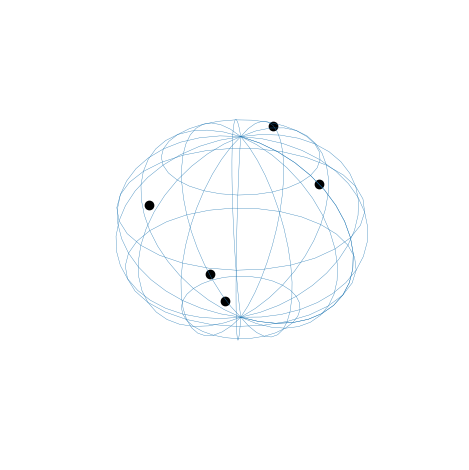

In [19]:
u, v = np.mgrid[0:2*np.pi:30j, 0:np.pi:20j]
x_sphere = np.cos(u) * np.sin(v)
y_sphere = np.sin(u) * np.sin(v)
z_sphere = np.cos(v)
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.grid(False)
plt.axis('off')
ax.plot_wireframe(x_sphere, y_sphere, z_sphere, antialiased=True, linewidth=0.25, rstride=2, cstride=4)
#ax.contour3D(x_sphere, y_sphere, z_sphere, 15, cmap='binary')
#ax.plot3D(np.cos(phi) * np.sin(theta), np.sin(phi) * np.sin(theta), np.cos(theta), 'bo')
ax.plot3D(x_sol, y_sol, z_sol, 'ko')
ls = LightSource(azdeg=315, altdeg=45)
#ax.plot_trisurf(x_sol, y_sol, z_sol, color='grey', alpha=0.5, shade=True, lightsource=ls)

#točke = np.array(list(zip(x_sol,y_sol,z_sol)))
#meja = ConvexHull(točke)
#for simplex in meja.simplices:
#    ax.plot(točke[simplex, 0], točke[simplex, 1], 'bo-')
plt.tight_layout()
#plt.savefig(f'slike/porazdelitev_n_{N}.pdf')
plt.show()

In [20]:
ameba = [[],[],[]]
powell = [[],[],[]]
cg = [[],[],[]]
bfgs = [[],[],[]]
N = 5  #dimenzije - št nabojev
for i in range(2, 1+N):
    print(i)
    phi = np.random.random(i-1) * 2*const.pi
    theta = np.random.random(i-1) * const.pi
    phi = np.insert(phi, 0, 0)
    theta = np.insert(theta, 0, 0)
    x = []
    for i,j in zip(phi, theta):
        x.append(i)
        x.append(j)
    reš_nm = minimize(energija, x0=x, method='Nelder-Mead')
    reš_pow = minimize(energija, x0=x, method='Powell')
    reš_bfgs = minimize(energija, x0=x, method='BFGS')
    reš_cg = minimize(energija, x0=x, method='CG')
    #minimalna E
    ameba[0].append(reš_nm.fun)
    powell[0].append(reš_pow.fun)
    bfgs[0].append(reš_bfgs.fun)
    cg[0].append(reš_cg.fun)
    ameba[1].append(reš_nm.nfev)
    powell[1].append(reš_pow.nfev)
    bfgs[1].append(reš_bfgs.nfev)
    cg[1].append(reš_cg.nfev)
    powell[2].append(reš_pow.x)

2
3
4


5


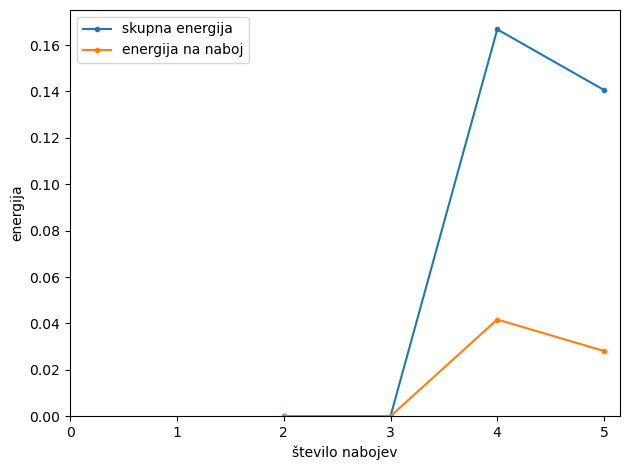

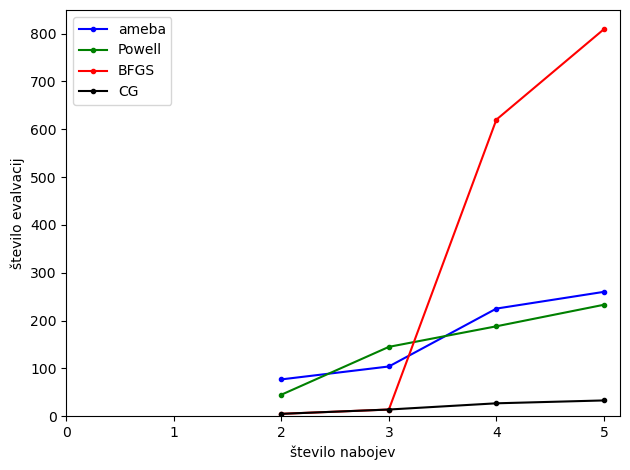

In [21]:
vrednosti = np.arange(2,1+N)
ameba_n = [ameba[0][i]/(i+2) for i in range(0,len(ameba[0]))]
powell_n = [powell[0][i]/(i+2) for i in range(0,len(powell[0]))]
bfgs_n = [bfgs[0][i]/(i+2) for i in range(0,len(bfgs[0]))]
cg_n = [cg[0][i]/(i+2) for i in range(0,len(cg[0]))]
skupna_E = [np.average([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]]) for i in range(len(ameba[0]))]
error_max = [abs(max([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]]) - np.average([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]])) for i in range(len(ameba[0]))]
error_min = [abs(min([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]]) - np.average([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]])) for i in range(len(ameba[0]))]
error = [error_min, error_max]
skupna_E_n = [np.average([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]])/(i+2) for i in range(len(ameba[0]))]
error_max_n = [abs(max([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]]) - np.average([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]])) / (i+2) for i in range(len(ameba[0]))]
error_min_n = [abs(min([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]]) - np.average([ameba[0][i], powell[0][i], bfgs[0][i], cg[0][i]])) / (i+2) for i in range(len(ameba[0]))]
error_n = [error_min_n, error_max_n]

plt.errorbar(vrednosti, skupna_E, fmt='.-', capsize=3, label='skupna energija')
plt.errorbar(vrednosti, skupna_E_n, fmt='.-', capsize=3, label='energija na naboj')
plt.xlim(xmin=0.0)
plt.ylim(ymin=0.0)
plt.legend()
plt.xlabel('število nabojev')
plt.ylabel('energija')
plt.tight_layout()
#plt.savefig('skupna_E_in_E_na_delec.pdf')
plt.show()
plt.plot(vrednosti, ameba[1], 'b.-', label='ameba')
plt.plot(vrednosti, powell[1], 'g.-', label='Powell')
plt.plot(vrednosti, bfgs[1], 'r.-', label='BFGS')
plt.plot(vrednosti, cg[1], 'k.-', label='CG')
plt.legend()
plt.xlim(xmin=0.0)
plt.ylim(ymin=0.0)
plt.xlabel('število nabojev')
plt.ylabel('število evalvacij')
plt.tight_layout()
#plt.savefig('št_iteracij.pdf')
plt.show()

In [22]:
#razdalja med točkami ???
phi_r = []
theta_r = []
točke = []
for i in range(len(powell[0])):
    aa = []
    bb = []
    for j in range(int(len(powell[2][i])/2)):
        aa.append(powell[2][i][2*j])
        bb.append(powell[2][i][2*j+1])
    phi_r.append(aa)
    theta_r.append(aa)
    točke.append(list(zip(aa, bb)))
#razdalje = []
#for r in range(len(phi_sol)):
#    razdalje.append([razdalja(phi[i], theta[i], phi[i-1], theta[i-1]) for i in range(1,len(phi_sol[r])) for j in range(1,len(theta_sol[r]))])
for i in range(len(powell[0])):
    kombinacije = list(itertools.combinations(točke[i],2))
    distances = [j*k for j,k in itertools.combinations(točke[i],2)]
    #for combo in kombinacije:
    #    point1, point2 = combo
    #    print(point1, point2)
    #   distance = razdalja(point1[0], point1[1], point2[0], point2[1])
    #    distances.append(list(distance))
    print(kombinacije)

TypeError: can't multiply sequence by non-int of type 'tuple'